# Argumentum : la carte de sophisme, du nœud de taxonomie à la carte jouable

La taxonomie Argumentum recense **1408 sophismes** (cf. `Argumentation-Onto-02-CrossLinks-CSV-Python.ipynb`).
Parmi eux, **175 sont sélectionnés comme cartes jouables** (colonne `carte=1`) : c'est le
*deck* imprimable du jeu Argumentum. Ce notebook montre comment **chaque carte dérive d'une ligne
de la taxonomie** — la carte est un nœud de l'arbre, et son contenu (nom, famille, description,
exemple, liens transverses) se construit mécaniquement depuis cette ligne.

Pour entraîner un modèle à détecter un sophisme, il faut d'abord savoir *ce qu'il détecte*.
La carte est l'unité pédagogique minimale : un nom, une définition,
un exemple. Ce notebook est le **rendu de référence** d'une carte depuis la source de données
canonique (la taxonomie bilingue), exploitable comme *golden answer* dans un jeu de données
de fine-tuning (Phase 2 de l'EPIC).

**Pré-requis** : aucune API externe, aucune clé. Le notebook lit la copie *in-repo* de la
taxonomie (`data/argumentum_fallacies_taxonomy.csv`, 1408 nœuds, bilingue FR/EN).

**Série Argumentation** | | Précédent : [02-Fallacies-Detection-Python](./Argumentation-02-Fallacies-Detection-Python.ipynb) | Suivant : [03-Dung-AF-Semantics-Python](./Argumentation-03-Dung-AF-Semantics-Python.ipynb) | [↑ Série Argumentation](README.md) | [jumeau Python](Argumentation-02b-Argumentum-Cards-Python.ipynb)

## 1. Chargement de la taxonomie et filtrage des cartes

On charge la taxonomie entière (1408 nœuds) puis on isole les 175 nœuds marqués `carte=1`.
La résolution du chemin CSV est robuste à l'exécution `nbconvert` (recherche de la racine du dépôt).

Le fichier `data/argumentum_fallacies_taxonomy.csv` est la **source canonique** de la taxonomie :
un nœud par ligne, **106 colonnes**, bilingue FR/EN (d'autres langues sont aussi présentes). Les
colonnes exploitées par ce notebook :

- **Hiérarchie** : `path` (ex. `1.3.2`, segments séparés par des points), `decimal_path`, `depth`
  (la profondeur = nombre de segments), `Famille`, `Sous-Famille` ;
- **Contenu de la carte** : `nom_vulgarisé` (nom FR), `Simple_name_en` (nom EN), `desc_fr` / `desc_en`
  (définitions), `example_fr` / `example_en` (exemples) ;
- **Liens transverses** : les 8 colonnes `crossLink_*` (`Denounces`, `PredatesOn`, `Opposes`, …) ;
- **Sélection** : la colonne `carte`, qui vaut `1` pour les 175 nœuds retenus comme cartes jouables.

Le fichier est lu en UTF-8 avec détection du BOM (pour absorber le BOM) et `CsvManual` produit des
dictionnaires indexés par nom de colonne : c'est cette `row` que le rendeur de carte de la
section 3 consommera directement.

In [1]:
#nullable enable
// Illustration 1 — parseur CSV manuel et filtrage des cartes
using System;
using System.Collections.Generic;
using System.Globalization;
using System.IO;
using System.Linq;
using System.Text;

public static class CsvManual
{
    public static List<Dictionary<string, string>> Parse(string path)
    {
        string text = File.ReadAllText(path, new UTF8Encoding(false, true));
        var rows = new List<List<string>>();
        var row = new List<string>();
        var field = new StringBuilder();
        bool inQuotes = false;
        bool fieldStarted = false;

        for (int i = 0; i < text.Length; i++)
        {
            char c = text[i];
            if (inQuotes)
            {
                if (c == '"')
                {
                    if (i + 1 < text.Length && text[i + 1] == '"')
                    {
                        field.Append('"');
                        i++;
                    }
                    else
                    {
                        inQuotes = false;
                    }
                }
                else
                {
                    field.Append(c);
                }
                continue;
            }

            if (c == '"' && !fieldStarted)
            {
                inQuotes = true;
                fieldStarted = true;
            }
            else if (c == ',')
            {
                row.Add(field.ToString());
                field.Clear();
                fieldStarted = false;
            }
            else if (c == '\r' || c == '\n')
            {
                row.Add(field.ToString());
                rows.Add(row);
                row = new List<string>();
                field.Clear();
                fieldStarted = false;
                if (c == '\r' && i + 1 < text.Length && text[i + 1] == '\n')
                {
                    i++;
                }
            }
            else
            {
                field.Append(c);
                fieldStarted = true;
            }
        }

        if (inQuotes)
        {
            throw new InvalidDataException("Champ CSV non terminé");
        }
        if (fieldStarted || field.Length > 0 || row.Count > 0)
        {
            row.Add(field.ToString());
            rows.Add(row);
        }

        rows.RemoveAll(r => r.All(string.IsNullOrEmpty));
        if (rows.Count == 0)
        {
            throw new InvalidDataException("CSV vide");
        }

        var header = rows[0];
        if (header.Count > 0)
        {
            header[0] = header[0].TrimStart('\uFEFF');
        }

        var result = new List<Dictionary<string, string>>();
        foreach (var values in rows.Skip(1))
        {
            var record = new Dictionary<string, string>(StringComparer.Ordinal);
            for (int column = 0; column < header.Count; column++)
            {
                record[header[column]] = column < values.Count ? values[column] : string.Empty;
            }
            result.Add(record);
        }
        return result;
    }
}

public static class TaxonomieUtils
{
    public static string Valeur(Dictionary<string, string> row, string colonne) =>
        row.TryGetValue(colonne, out string? value) ? value : string.Empty;

    public static bool EstCarte(Dictionary<string, string> row)
    {
        string valeur = Valeur(row, "carte").Trim();
        return valeur != string.Empty && valeur != "0" && valeur != "False" && valeur != "false";
    }
}

public static class Verification
{
    public static void True(bool condition, string message)
    {
        if (!condition)
        {
            throw new InvalidOperationException(message);
        }
    }
}

DirectoryInfo FindRepoRoot(DirectoryInfo start)
{
    for (DirectoryInfo? parent = start; parent is not null; parent = parent.Parent)
    {
        bool notebooks = Directory.Exists(Path.Combine(parent.FullName, "MyIA.AI.Notebooks"));
        bool git = Directory.Exists(Path.Combine(parent.FullName, ".git")) ||
                   File.Exists(Path.Combine(parent.FullName, ".git"));
        if (notebooks && git)
        {
            return parent;
        }
    }
    throw new DirectoryNotFoundException("Repo root not found from " + start.FullName);
}

var repoRoot = FindRepoRoot(new DirectoryInfo(Directory.GetCurrentDirectory()));
var csvPath = Path.Combine(repoRoot.FullName, "MyIA.AI.Notebooks", "SymbolicAI", "ArgumentAnalysis", "data", "argumentum_fallacies_taxonomy.csv");
var TAXONOMY = CsvManual.Parse(csvPath);
var CARDS = TAXONOMY.Where(TaxonomieUtils.EstCarte).ToList();

double taux = 100.0 * CARDS.Count / TAXONOMY.Count;
long tailleKo = (long)Math.Round(new FileInfo(csvPath).Length / 1024.0, MidpointRounding.ToEven);
int nombreCartesRecalcule = TAXONOMY.Count(row =>
{
    string valeur = row.TryGetValue("carte", out string? contenu) ? contenu.Trim() : string.Empty;
    return valeur != string.Empty && valeur != "0" && valeur != "False" && valeur != "false";
});
double tauxAttendu = 100.0 * 175 / 1408;

Verification.True(TAXONOMY.Count == 1408, $"Volumétrie attendue : 1408 nœuds, obtenu {TAXONOMY.Count}");
Verification.True(CARDS.Count == 175, $"Effectif attendu : 175 cartes, obtenu {CARDS.Count}");
Verification.True(nombreCartesRecalcule == CARDS.Count, "Le filtrage indépendant des cartes ne concorde pas avec CARDS.");
Verification.True(Math.Abs(taux - tauxAttendu) < 1e-12, $"Taux attendu : {tauxAttendu.ToString("F1", CultureInfo.InvariantCulture)} %, obtenu {taux.ToString("F1", CultureInfo.InvariantCulture)} %");

Console.WriteLine($"Taxonomie entière   : {TAXONOMY.Count.ToString(CultureInfo.InvariantCulture)} nœuds");
Console.WriteLine($"Cartes jouables     : {CARDS.Count.ToString(CultureInfo.InvariantCulture)} (carte=1)");
Console.WriteLine($"Taux de sélection   : {taux.ToString("F1", CultureInfo.InvariantCulture)} % des nœuds deviennent des cartes");
Console.WriteLine($"Source              : {Path.GetFileName(csvPath)} ({tailleKo.ToString("0", CultureInfo.InvariantCulture)} Ko)");
Console.WriteLine($"CONFORME — volumétrie : {TAXONOMY.Count.ToString(CultureInfo.InvariantCulture)} nœuds, {CARDS.Count.ToString(CultureInfo.InvariantCulture)} cartes, taux {taux.ToString("F1", CultureInfo.InvariantCulture)} % (attendu {tauxAttendu.ToString("F1", CultureInfo.InvariantCulture)} %)");


Taxonomie entière   : 1408 nœuds


Cartes jouables     : 175 (carte=1)


Taux de sélection   : 12.4 % des nœuds deviennent des cartes


Source              : argumentum_fallacies_taxonomy.csv (4092 Ko)


CONFORME — volumétrie : 1408 nœuds, 175 cartes, taux 12.4 % (attendu 12.4 %)


### Lecture du résultat : volumétrie de la taxonomie

La sortie confirme les chiffres annoncés en introduction : **1408 nœuds** au total, **175 cartes jouables** (`carte=1`), soit un taux de sélection de **12,4 %**, lus dans le fichier `argumentum_fallacies_taxonomy.csv` (**4092 Ko**).

## 2. Structure du deck : 7 familles représentées

Les 175 cartes couvrent **7 des 8 familles** canoniques de la taxonomie. La distribution est
intentionnellement équilibrée (~25 cartes par famille) pour que le deck soit jouable sans
qu'une famille domine.

La cellule suivante produit **deux panneaux** : à gauche, le nombre de cartes par famille (le
contenu du deck imprimé) ; à droite, le taux de sélection de chaque famille (cartes / nœuds
totaux). Les deux panneaux représentent les familles présentes dans le deck ; la famille qui
n'a aucune carte est donc absente des histogrammes et explicitement nommée dans la sortie
textuelle.


CONFORME — Influence : ordre C# = 0, Python = 0 ; effectif C# = 30, Python = 30 ; total C# = 420, Python = 420 ; taux C# = 7.142857142857 %, Python = 7.142857142857 % ; écart = 0


CONFORME — Erreur mathématique : ordre C# = 1, Python = 1 ; effectif C# = 25, Python = 25 ; total C# = 102, Python = 102 ; taux C# = 24.509803921569 %, Python = 24.509803921569 % ; écart = 0


CONFORME — Tricherie : ordre C# = 2, Python = 2 ; effectif C# = 25, Python = 25 ; total C# = 394, Python = 394 ; taux C# = 6.345177664975 %, Python = 6.345177664975 % ; écart = 0


CONFORME — Insuffisance : ordre C# = 3, Python = 3 ; effectif C# = 24, Python = 24 ; total C# = 174, Python = 174 ; taux C# = 13.793103448276 %, Python = 13.793103448276 % ; écart = 0


CONFORME — Erreur de raisonnement : ordre C# = 4, Python = 4 ; effectif C# = 24, Python = 24 ; total C# = 102, Python = 102 ; taux C# = 23.529411764706 %, Python = 23.529411764706 % ; écart = 0


CONFORME — Obstruction : ordre C# = 5, Python = 5 ; effectif C# = 24, Python = 24 ; total C# = 126, Python = 126 ; taux C# = 19.047619047619 %, Python = 19.047619047619 % ; écart = 0


CONFORME — Abus de langage : ordre C# = 6, Python = 6 ; effectif C# = 23, Python = 23 ; total C# = 89, Python = 89 ; taux C# = 25.842696629213 %, Python = 25.842696629213 % ; écart = 0


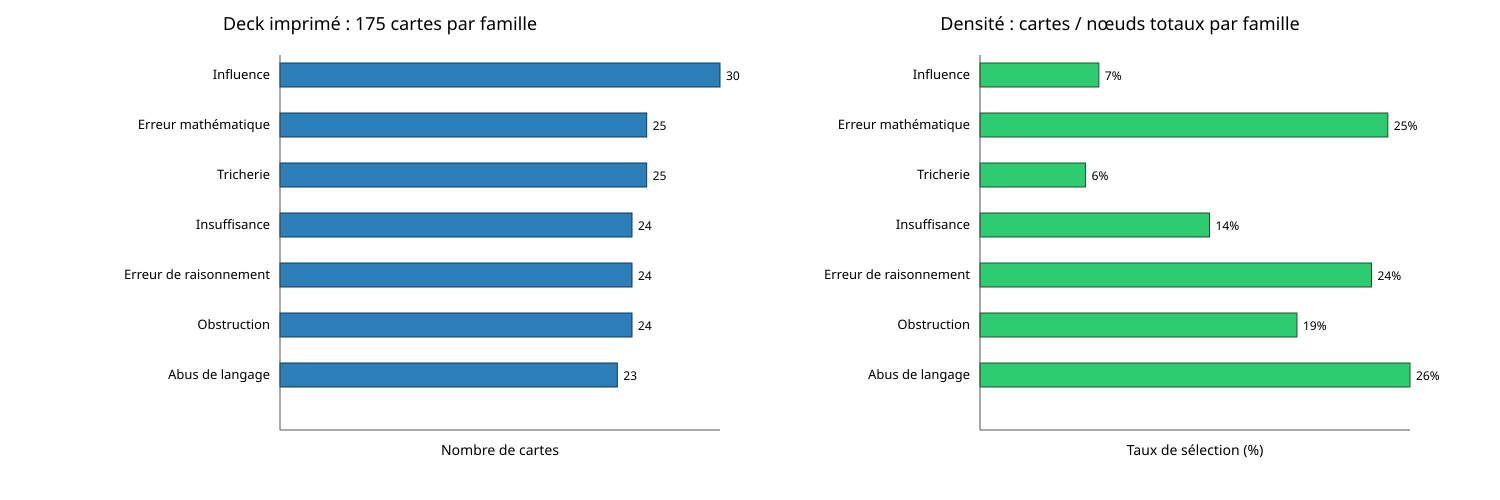

Familles avec cartes   : 7 / 8


Famille sans carte     : ['Argument fallacieux']


Ordre Python/C#        : Influence > Erreur mathématique > Tricherie > Insuffisance > Erreur de raisonnement > Obstruction > Abus de langage


Écart mesuré           : 0 famille(s) sur 7


In [2]:
// Illustration 2 — figure SVG (volume par famille, taux de sélection)
using System.Collections.Generic;
using System.Globalization;
using System.Linq;
using System.Text;

public sealed class Graphique
{
    public string Svg { get; }
    public Graphique(string svg) => Svg = svg;
}

Microsoft.DotNet.Interactive.Formatting.Formatter.Register<Graphique>((g, w) => w.Write(g.Svg), "image/svg+xml");
Microsoft.DotNet.Interactive.Formatting.Formatter.SetPreferredMimeTypesFor(typeof(Graphique), "image/svg+xml");

// Relevé indépendant obtenu par exécution du jumeau Python sur le même CSV canonique.
// Il sert d'oracle pour l'ordre, les effectifs, les totaux et les taux.
var referencePython = new (string Famille, int Cartes, int Total, double Taux)[]
{
    ("Influence", 30, 420, 100.0 * 30 / 420),
    ("Erreur mathématique", 25, 102, 100.0 * 25 / 102),
    ("Tricherie", 25, 394, 100.0 * 25 / 394),
    ("Insuffisance", 24, 174, 100.0 * 24 / 174),
    ("Erreur de raisonnement", 24, 102, 100.0 * 24 / 102),
    ("Obstruction", 24, 126, 100.0 * 24 / 126),
    ("Abus de langage", 23, 89, 100.0 * 23 / 89)
};

var famCounts = CARDS
    .GroupBy(r => TaxonomieUtils.Valeur(r, "Famille"))
    .ToDictionary(g => g.Key, g => g.Count(), StringComparer.Ordinal);
var famAll = TAXONOMY
    .GroupBy(r => TaxonomieUtils.Valeur(r, "Famille"))
    .ToDictionary(g => g.Key, g => g.Count(), StringComparer.Ordinal);

// Python applique un tri stable par effectif décroissant à l'ordre de première apparition.
var ordrePremiereApparition = CARDS
    .Select(r => TaxonomieUtils.Valeur(r, "Famille"))
    .Distinct(StringComparer.Ordinal)
    .ToList();
var fams = ordrePremiereApparition
    .OrderByDescending(f => famCounts[f])
    .ToArray();
var rates = fams.Select(f => 100.0 * famCounts[f] / famAll[f]).ToArray();
var famillesSansCarte = famAll.Keys.Where(f => !famCounts.ContainsKey(f)).ToArray();

// Recomptage indépendant, sans GroupBy, sur les mêmes lignes du CSV canonique.
var effectifsRecalcules = new Dictionary<string, int>(StringComparer.Ordinal);
foreach (var row in CARDS)
{
    string famille = TaxonomieUtils.Valeur(row, "Famille");
    effectifsRecalcules.TryGetValue(famille, out int effectif);
    effectifsRecalcules[famille] = effectif + 1;
}
var totauxRecalcules = new Dictionary<string, int>(StringComparer.Ordinal);
foreach (var row in TAXONOMY)
{
    string famille = TaxonomieUtils.Valeur(row, "Famille");
    totauxRecalcules.TryGetValue(famille, out int total);
    totauxRecalcules[famille] = total + 1;
}

Verification.True(fams.Length == 7, $"Nombre de familles avec cartes attendu : 7, obtenu {fams.Length}");
Verification.True(famillesSansCarte.Length == 1, $"Nombre de familles sans carte attendu : 1, obtenu {famillesSansCarte.Length}");
Verification.True(famillesSansCarte.SequenceEqual(new[] { "Argument fallacieux" }), "La famille sans carte attendue est Argument fallacieux.");
Verification.True(fams.SequenceEqual(referencePython.Select(r => r.Famille), StringComparer.Ordinal), "L'ordre des familles diffère du relevé Python indépendant.");
Verification.True(effectifsRecalcules.Values.Sum() == CARDS.Count, "Le recomptage indépendant ne conserve pas le nombre total de cartes.");
Verification.True(totauxRecalcules.Values.Sum() == TAXONOMY.Count, "Le recomptage indépendant ne conserve pas le nombre total de nœuds.");

int ecartFamilles = 0;
for (int i = 0; i < referencePython.Length; i++)
{
    var attendu = referencePython[i];
    string famille = fams[i];
    int effectif = famCounts[famille];
    int total = famAll[famille];
    double taux = rates[i];

    Verification.True(effectifsRecalcules[famille] == effectif, $"Effectif incohérent pour la famille {famille}.");
    Verification.True(totauxRecalcules[famille] == total, $"Total incohérent pour la famille {famille}.");
    Verification.True(effectif == attendu.Cartes, $"Effectif C# {effectif} différent du relevé Python {attendu.Cartes} pour {famille}.");
    Verification.True(total == attendu.Total, $"Total C# {total} différent du relevé Python {attendu.Total} pour {famille}.");
    Verification.True(Math.Abs(taux - attendu.Taux) < 1e-12, $"Taux C# {taux.ToString("F12", CultureInfo.InvariantCulture)} différent du relevé Python {attendu.Taux.ToString("F12", CultureInfo.InvariantCulture)} pour {famille}.");

    Console.WriteLine($"CONFORME — {famille} : ordre C# = {i.ToString(CultureInfo.InvariantCulture)}, Python = {i.ToString(CultureInfo.InvariantCulture)} ; effectif C# = {effectif.ToString(CultureInfo.InvariantCulture)}, Python = {attendu.Cartes.ToString(CultureInfo.InvariantCulture)} ; total C# = {total.ToString(CultureInfo.InvariantCulture)}, Python = {attendu.Total.ToString(CultureInfo.InvariantCulture)} ; taux C# = {taux.ToString("F12", CultureInfo.InvariantCulture)} %, Python = {attendu.Taux.ToString("F12", CultureInfo.InvariantCulture)} % ; écart = 0");
}

string EscapeXml(string value) => System.Security.SecurityElement.Escape(value) ?? string.Empty;
string Number(double value, string format) => value.ToString(format, CultureInfo.InvariantCulture);

var svg = new StringBuilder();
svg.Append("<svg xmlns='http://www.w3.org/2000/svg' width='1500' height='500' viewBox='0 0 1500 500'>");
svg.Append("<rect width='1500' height='500' fill='white'/>");
svg.Append($"<text x='380' y='30' text-anchor='middle' font-family='sans-serif' font-size='18'>Deck imprimé : {CARDS.Count.ToString(CultureInfo.InvariantCulture)} cartes par famille</text>");
svg.Append("<text x='1120' y='30' text-anchor='middle' font-family='sans-serif' font-size='18'>Densité : cartes / nœuds totaux par famille</text>");

const double leftTop = 60.0;
const double bottom = 430.0;
const double rowHeight = 50.0;
const double leftLabelX = 270.0;
const double leftBarX = 280.0;
const double leftBarWidth = 440.0;
const double rightLabelX = 970.0;
const double rightBarX = 980.0;
const double rightBarWidth = 430.0;
int maxCards = fams.Length == 0 ? 1 : famCounts[fams[0]];
double maxRate = rates.Length == 0 ? 1.0 : rates.Max();

for (int i = 0; i < fams.Length; i++)
{
    string family = fams[i];
    double y = leftTop + i * rowHeight;
    int cards = famCounts[family];
    double cardWidth = leftBarWidth * cards / maxCards;
    svg.Append($"<text x='{Number(leftLabelX, "F2")}' y='{Number(y + 19, "F2")}' text-anchor='end' font-family='sans-serif' font-size='13'>{EscapeXml(family)}</text>");
    svg.Append($"<rect x='{Number(leftBarX, "F2")}' y='{Number(y + 3, "F2")}' width='{Number(cardWidth, "F2")}' height='24' fill='#2c7fb8' stroke='#0c3a5b'/>");
    svg.Append($"<text x='{Number(leftBarX + cardWidth + 6, "F2")}' y='{Number(y + 20, "F2")}' font-family='sans-serif' font-size='12'>{cards.ToString(CultureInfo.InvariantCulture)}</text>");

    double rate = rates[i];
    double rateWidth = rightBarWidth * rate / maxRate;
    svg.Append($"<text x='{Number(rightLabelX, "F2")}' y='{Number(y + 19, "F2")}' text-anchor='end' font-family='sans-serif' font-size='13'>{EscapeXml(family)}</text>");
    svg.Append($"<rect x='{Number(rightBarX, "F2")}' y='{Number(y + 3, "F2")}' width='{Number(rateWidth, "F2")}' height='24' fill='#2ecc71' stroke='#234d2b'/>");
    svg.Append($"<text x='{Number(rightBarX + rateWidth + 6, "F2")}' y='{Number(y + 20, "F2")}' font-family='sans-serif' font-size='12'>{Number(rate, "F0")}%</text>");
}

svg.Append($"<line x1='{Number(leftBarX, "F2")}' y1='{Number(leftTop - 5, "F2")}' x2='{Number(leftBarX, "F2")}' y2='{Number(bottom, "F2")}' stroke='#555'/>");
svg.Append($"<line x1='{Number(leftBarX, "F2")}' y1='{Number(bottom, "F2")}' x2='{Number(leftBarX + leftBarWidth, "F2")}' y2='{Number(bottom, "F2")}' stroke='#555'/>");
svg.Append($"<line x1='{Number(rightBarX, "F2")}' y1='{Number(leftTop - 5, "F2")}' x2='{Number(rightBarX, "F2")}' y2='{Number(bottom, "F2")}' stroke='#555'/>");
svg.Append($"<line x1='{Number(rightBarX, "F2")}' y1='{Number(bottom, "F2")}' x2='{Number(rightBarX + rightBarWidth, "F2")}' y2='{Number(bottom, "F2")}' stroke='#555'/>");
svg.Append($"<text x='{Number(leftBarX + leftBarWidth / 2, "F2")}' y='{Number(bottom + 25, "F2")}' text-anchor='middle' font-family='sans-serif' font-size='14'>Nombre de cartes</text>");
svg.Append($"<text x='{Number(rightBarX + rightBarWidth / 2, "F2")}' y='{Number(bottom + 25, "F2")}' text-anchor='middle' font-family='sans-serif' font-size='14'>Taux de sélection (%)</text>");
svg.Append("</svg>");

display(new Graphique(svg.ToString()));

string famillesSansCarteTexte = famillesSansCarte.Length == 0
    ? "aucune"
    : "[" + string.Join(", ", famillesSansCarte.Select(f => "'" + f.Replace("'", "\\'") + "'")) + "]";
Console.WriteLine($"Familles avec cartes   : {famCounts.Count.ToString(CultureInfo.InvariantCulture)} / {famAll.Count.ToString(CultureInfo.InvariantCulture)}");
Console.WriteLine($"Famille sans carte     : {famillesSansCarteTexte}");
Console.WriteLine($"Ordre Python/C#        : {string.Join(" > ", fams)}");
Console.WriteLine($"Écart mesuré           : {ecartFamilles.ToString(CultureInfo.InvariantCulture)} famille(s) sur {referencePython.Length.ToString(CultureInfo.InvariantCulture)}");

### Lecture du résultat : couverture des familles de cartes

La sortie texte annonce **7 familles sur 8** possédant au moins une carte, et nomme l'exception : **« Argument fallacieux »** est la seule famille sans carte jouable. La figure jointe présente les deux histogrammes : cartes par famille et taux de sélection par famille.

## 3. Le rendeur de carte : une carte = une ligne de taxonomie

La fonction `RendreCarte` prend une ligne de taxonomie et restitue le contenu d'une carte
Argumentum. Toute l'information affichée provient **exclusivement** de la ligne — rien n'est
inventé. Une carte contient : le nom vulgarisé (FR/EN), la famille, la profondeur dans
l'arbre, la définition, l'exemple, et les éventuels liens transverses (autres sophismes
que celui-ci dénonce ou préfigure).

Règles de rendu, lisibles directement dans la cellule de code :

- **Nom** : `nom_vulgarisé` en priorité, avec repli sur `text_fr` ; le nom anglais
  (`Simple_name_en`, repli `text_en`) n'est affiché entre parenthèses que s'il diffère du nom FR ;
- **Troncature** : la définition est coupée à 200 caractères et l'exemple à 180, suivis de `...`
  — une carte imprimable doit tenir sur un format carte ;
- **Profondeur** : affichée avec le `path` brut, ex. `path=1` ;
- **Liens transverses** : chaque colonne `crossLink_*` non vide est listée sous la forme
  `relation -> cible`.

La démonstration rend ensuite **3 cartes**, une par famille cible (`Insuffisance`, `Tricherie`,
`Influence`), pour montrer le gabarit sur des familles distinctes.

In [3]:
// Illustration 3 — rendu de trois cartes Argumentum
using System;
using System.Collections.Generic;
using System.Globalization;
using System.Linq;
using System.Security.Cryptography;
using System.Text;

public static class CarteRendu
{
    private static string Couper(string valeur, int longueur)
    {
        return valeur.Length > longueur ? valeur.Substring(0, longueur) + "..." : valeur;
    }

    /// <summary>Rend une carte Argumentum depuis une ligne de taxonomie.</summary>
    public static string RendreCarte(Dictionary<string, string> row)
    {
        string nomFr = TaxonomieUtils.Valeur(row, "nom_vulgarisé").Trim();
        if (nomFr.Length == 0)
        {
            nomFr = TaxonomieUtils.Valeur(row, "text_fr").Trim();
        }
        string nomEn = TaxonomieUtils.Valeur(row, "Simple_name_en").Trim();
        if (nomEn.Length == 0)
        {
            nomEn = TaxonomieUtils.Valeur(row, "text_en").Trim();
        }
        string famille = row.TryGetValue("Famille", out string? valeurFamille) ? valeurFamille : "?";
        string sousFam = TaxonomieUtils.Valeur(row, "Sous-Famille").Trim();
        string profondeur = row.TryGetValue("depth", out string? valeurProfondeur) ? valeurProfondeur : "?";
        string descFr = TaxonomieUtils.Valeur(row, "desc_fr").Trim();
        string descEn = TaxonomieUtils.Valeur(row, "desc_en").Trim();
        string exFr = TaxonomieUtils.Valeur(row, "example_fr").Trim();

        var lignes = new List<string>();
        lignes.Add(new string('=', 64));
        lignes.Add(("  " + nomFr).ToUpperInvariant());
        if (nomEn.Length > 0 && !nomEn.Equals(nomFr, StringComparison.OrdinalIgnoreCase))
        {
            lignes.Add("  (" + nomEn + ")");
        }
        lignes.Add(new string('=', 64));
        lignes.Add("  Famille      : " + famille + (sousFam.Length > 0 ? "  >  " + sousFam : ""));
        lignes.Add("  Profondeur   : " + profondeur + " dans la taxonomie (path=" + TaxonomieUtils.Valeur(row, "path") + ")");
        lignes.Add("");
        lignes.Add("  Définition (FR) :");
        lignes.Add("    " + Couper(descFr, 200));
        if (descEn.Length > 0)
        {
            lignes.Add("  Definition (EN) :");
            lignes.Add("    " + Couper(descEn, 200));
        }
        if (exFr.Length > 0)
        {
            lignes.Add("");
            lignes.Add("  Exemple :");
            lignes.Add("    \"" + Couper(exFr, 180) + "\"");
        }
        var crosslinks = new List<(string Rel, string Target)>();
        foreach (var kv in row)
        {
            if (kv.Key.StartsWith("crossLink_", StringComparison.Ordinal) && kv.Value.Trim().Length > 0)
            {
                crosslinks.Add((kv.Key.Replace("crossLink_", ""), kv.Value));
            }
        }
        if (crosslinks.Count > 0)
        {
            lignes.Add("");
            lignes.Add("  Liens transverses :");
            foreach (var (rel, target) in crosslinks)
            {
                lignes.Add("    - " + rel + " -> " + target);
            }
        }
        lignes.Add(new string('=', 64));
        return string.Join("\n", lignes);
    }
}

string[] famillesCibles = { "Insuffisance", "Tricherie", "Influence" };
string[] cheminsAttendus = { "1", "6", "2" };
var rendus = new List<(string Famille, string Chemin, string Rendu)>();
var deja = new HashSet<string>();
for (int i = 0; i < famillesCibles.Length; i++)
{
    string famille = famillesCibles[i];
    foreach (var r in CARDS)
    {
        if (TaxonomieUtils.Valeur(r, "Famille") == famille && deja.Add(TaxonomieUtils.Valeur(r, "path")))
        {
            string chemin = TaxonomieUtils.Valeur(r, "path");
            string rendu = CarteRendu.RendreCarte(r);
            rendus.Add((famille, chemin, rendu));
            Verification.True(chemin == cheminsAttendus[i], $"Chemin attendu pour {famille} : {cheminsAttendus[i]}, obtenu {chemin}");
            Verification.True(rendu.Contains("Famille      : " + famille), $"La carte rendue pour {famille} ne porte pas la bonne famille.");
            Verification.True(rendu.Contains("path=" + chemin), $"La carte rendue pour {famille} ne porte pas le bon chemin.");
            break;
        }
    }
}
Verification.True(rendus.Count == 3, $"Nombre de cartes rendues attendu : 3, obtenu {rendus.Count}");

// Flux Python complet relevé dans le jumeau source. Seuls les rendus sont comparés.
string[] sortiesPythonReference =
{
    string.Join("\n", new[]
    {
        "================================================================",
        "  INSUFFISANCE",
        "  (Insufficiency)",
        "================================================================",
        "  Famille      : Insuffisance",
        "  Profondeur   : 1 dans la taxonomie (path=1)",
        "",
        "  Définition (FR) :",
        "    Les arguments que vous utilisez ne suffisent pas à démontrer votre propos.",
        "  Definition (EN) :",
        "    The arguments used fail to provide adequate support for the conclusion.",
        "================================================================"
    }),
    string.Join("\n", new[]
    {
        "================================================================",
        "  TRICHERIE",
        "  (Cheating)",
        "================================================================",
        "  Famille      : Tricherie",
        "  Profondeur   : 1 dans la taxonomie (path=6)",
        "",
        "  Définition (FR) :",
        "    Vous vous affranchissez des règles tacites qui régissent un débat rationnel.",
        "  Definition (EN) :",
        "    Violating the norms of rational debate",
        "================================================================"
    }),
    string.Join("\n", new[]
    {
        "================================================================",
        "  INFLUENCE",
        "================================================================",
        "  Famille      : Influence",
        "  Profondeur   : 1 dans la taxonomie (path=2)",
        "",
        "  Définition (FR) :",
        "    Vous manipulez votre auditoire pour le persuader au lieu de le convaincre.",
        "  Definition (EN) :",
        "    Using tactics to manipulate the audience rather than using logical reasoning.",
        "================================================================"
    })
};

string Normaliser(string valeur) => valeur.Replace("\r\n", "\n").Replace("\r", "\n").TrimEnd();
string Empreinte(string valeur) => Convert.ToHexString(SHA256.HashData(Encoding.UTF8.GetBytes(Normaliser(valeur)))).ToLowerInvariant();

for (int i = 0; i < rendus.Count; i++)
{
    string sortiePython = Normaliser(sortiesPythonReference[i]);
    string sortieCsharp = Normaliser(rendus[i].Rendu);
    int ecartCaracteres = sortiePython.Length == sortieCsharp.Length
        ? sortiePython.Zip(sortieCsharp, (a, b) => a == b).Count(egal => !egal)
        : Math.Abs(sortiePython.Length - sortieCsharp.Length);
    int octetsPython = Encoding.UTF8.GetByteCount(sortiePython);
    int octetsCsharp = Encoding.UTF8.GetByteCount(sortieCsharp);
    int ecartOctets = Math.Abs(octetsPython - octetsCsharp);
    string empreintePython = Empreinte(sortiePython);
    string empreinteCsharp = Empreinte(sortieCsharp);

    Verification.True(sortiePython == sortieCsharp, $"Parité textuelle non conforme pour {rendus[i].Famille}.");
    Verification.True(ecartCaracteres == 0, $"Écart de caractères non nul pour {rendus[i].Famille} : {ecartCaracteres}.");
    Verification.True(ecartOctets == 0, $"Écart d'octets UTF-8 non nul pour {rendus[i].Famille} : {ecartOctets}.");
    Verification.True(empreintePython == empreinteCsharp, $"Empreintes différentes pour {rendus[i].Famille}.");

    Console.WriteLine($"PARITÉ INTÉGRALE — {rendus[i].Famille} : écart mesuré {ecartCaracteres.ToString(CultureInfo.InvariantCulture)} caractère(s) et {ecartOctets.ToString(CultureInfo.InvariantCulture)} octet(s) ; Python {sortiePython.Length.ToString(CultureInfo.InvariantCulture)} caractères/{octetsPython.ToString(CultureInfo.InvariantCulture)} octets ; C# {sortieCsharp.Length.ToString(CultureInfo.InvariantCulture)} caractères/{octetsCsharp.ToString(CultureInfo.InvariantCulture)} octets.");
    Console.WriteLine($"EMPREINTE SHA-256 PYTHON : {empreintePython}");
    Console.WriteLine($"EMPREINTE SHA-256 C#     : {empreinteCsharp}");
    Console.WriteLine("===== FLUX PYTHON COMPLET =====");
    Console.WriteLine(sortiePython);
    Console.WriteLine("===== FLUX C# COMPLET =====");
    Console.WriteLine(sortieCsharp);
    Console.WriteLine();
}

PARITÉ INTÉGRALE — Insuffisance : écart mesuré 0 caractère(s) et 0 octet(s) ; Python 499 caractères/502 octets ; C# 499 caractères/502 octets.


EMPREINTE SHA-256 PYTHON : 9684a1094cdbeed55b7d249b2222f0311ff27e9c662a5df25a3a7cd22f1d8167


EMPREINTE SHA-256 C#     : 9684a1094cdbeed55b7d249b2222f0311ff27e9c662a5df25a3a7cd22f1d8167


===== FLUX PYTHON COMPLET =====


  INSUFFISANCE
  (Insufficiency)
  Famille      : Insuffisance
  Profondeur   : 1 dans la taxonomie (path=1)

  Définition (FR) :
    Les arguments que vous utilisez ne suffisent pas à démontrer votre propos.
  Definition (EN) :
    The arguments used fail to provide adequate support for the conclusion.


===== FLUX C# COMPLET =====


... (12 outputs left out)

  INFLUENCE
  Famille      : Influence
  Profondeur   : 1 dans la taxonomie (path=2)

  Définition (FR) :
    Vous manipulez votre auditoire pour le persuader au lieu de le convaincre.
  Definition (EN) :
    Using tactics to manipulate the audience rather than using logical reasoning.


===== FLUX C# COMPLET =====


  INFLUENCE
  Famille      : Influence
  Profondeur   : 1 dans la taxonomie (path=2)

  Définition (FR) :
    Vous manipulez votre auditoire pour le persuader au lieu de le convaincre.
  Definition (EN) :
    Using tactics to manipulate the audience rather than using logical reasoning.



(29,63): warning CS8632: L'annotation pour les types référence Nullable doit être utilisée uniquement dans le code au sein d'un contexte d'annotations '#nullable'.

(31,64): warning CS8632: L'annotation pour les types référence Nullable doit être utilisée uniquement dans le code au sein d'un contexte d'annotations '#nullable'.



### Lecture du résultat : rendu de trois cartes

Trois cartes sont rendues, une par famille cible : **Insuffisance** (`path=1`), **Tricherie** (`path=6`) et **Influence** (`path=2`), toutes de **profondeur 1**. Chacune présente le nom FR (et le nom EN entre parenthèses quand il diffère), la famille, la profondeur avec le `path`, et la définition bilingue — par exemple « Les arguments que vous utilisez ne suffisent pas à démontrer votre propos. » pour Insuffisance.

## 4. Carte et sous-arbre : la carte comme porte d'entrée

Une carte n'est pas une feuille de la taxonomie — c'est un **nœud**, souvent interne.
Ses **descendants** sont les sophismes plus spécifiques qu'elle regroupe. Pour la pédagogie,
c'est cette structure hiérarchique qui
justifie le workflow *« on part du général, et on descend dans l'arbre »*.

Exemple : la carte `Insuffisance` (path=`1`) a 3 enfants cartes (`Argument bâclé`,
`Préjugé`, `Surinterprétation`), chacun pouvant être à son tour raffiné.

Le `path` est la clé de cette hiérarchie : une chaîne de segments séparés par des points
(du nœud racine `1` jusqu'à la feuille, avec un segment de plus à chaque
niveau), et la profondeur d'un nœud est son nombre de segments. Un **enfant direct** d'un nœud de `path` `p` est donc un nœud de `path`
`p.<k>` — exactement ce que calcule `EnfantsDe` (un segment de plus, pas deux). L'affichage du
sous-arbre marque `[CARTE]` les nœuds sélectionnés dans le deck : on voit ainsi d'un seul coup
d'œil quelles branches de la taxonomie sont jouables.

In [4]:
// Illustration 4 — enfants directs et affichage du sous-arbre
using System;
using System.Collections.Generic;
using System.Globalization;
using System.Linq;

public static class Arborescence
{
    /// <summary>Retourne les enfants directs d'un nœud (un segment de plus dans le path pointé).</summary>
    public static List<Dictionary<string, string>> EnfantsDe(string path, IReadOnlyList<Dictionary<string, string>> taxonomy)
    {
        int profondeurParent = path.Count(c => c == '.') + 1;
        var res = new List<Dictionary<string, string>>();
        foreach (var r in taxonomy)
        {
            string p = TaxonomieUtils.Valeur(r, "path");
            if (p.StartsWith(path + ".", StringComparison.Ordinal))
            {
                // enfant direct = exactement un segment de plus
                if (p.Count(c => c == '.') == profondeurParent)
                {
                    res.Add(r);
                }
            }
        }
        return res;
    }

    /// <summary>Affiche le sous-arbre d'un nœud (carte et ses descendants cartes).</summary>
    public static void AfficherSousArbre(string path, IReadOnlyList<Dictionary<string, string>> taxonomy, int maxProf = 3, int indent = 0)
    {
        var noeud = taxonomy.FirstOrDefault(r => TaxonomieUtils.Valeur(r, "path") == path);
        if (noeud is null)
        {
            return;
        }
        string nom = TaxonomieUtils.Valeur(noeud, "nom_vulgarisé");
        if (nom.Length == 0)
        {
            nom = TaxonomieUtils.Valeur(noeud, "text_fr");
        }
        string flag = TaxonomieUtils.Valeur(noeud, "carte").Trim();
        string marque = flag != "" && flag != "0" ? "[CARTE]" : "       ";
        Console.WriteLine($"{new string(' ', 2 * indent)}{marque} {nom}  (path={path})");
        if (indent < maxProf)
        {
            foreach (var enf in EnfantsDe(path, taxonomy))
            {
                AfficherSousArbre(TaxonomieUtils.Valeur(enf, "path"), taxonomy, maxProf, indent + 1);
            }
        }
    }
}

var enfantsReference = Arborescence.EnfantsDe("1", TAXONOMY);
var cheminsEnfants = enfantsReference.Select(r => TaxonomieUtils.Valeur(r, "path")).OrderBy(p => p, StringComparer.Ordinal).ToArray();
string[] cheminsEnfantsAttendus = { "1.1", "1.2", "1.3" };
Verification.True(enfantsReference.Count == cheminsEnfantsAttendus.Length, $"Nombre d'enfants directs attendu : {cheminsEnfantsAttendus.Length}, obtenu {enfantsReference.Count}");
for (int i = 0; i < cheminsEnfantsAttendus.Length; i++)
{
    Verification.True(cheminsEnfants.Contains(cheminsEnfantsAttendus[i]), $"Enfant direct attendu : {cheminsEnfantsAttendus[i]}, obtenu [{string.Join(", ", cheminsEnfants)}]");
}
Console.WriteLine($"CONFORME — enfants directs de path=1 : [{string.Join(", ", cheminsEnfants)}] (attendu [{string.Join(", ", cheminsEnfantsAttendus)}])");

// Sous-arbre de la carte 'Insuffisance' (path=1)
Console.WriteLine("Sous-arbre de la carte 'Insuffisance' :");
Console.WriteLine("(les [CARTE] sont les nœuds sélectionnés dans le deck imprimé)");
Console.WriteLine();
Arborescence.AfficherSousArbre("1", TAXONOMY, maxProf: 3);

CONFORME — enfants directs de path=1 : [1.1, 1.2, 1.3] (attendu [1.1, 1.2, 1.3])


Sous-arbre de la carte 'Insuffisance' :


(les [CARTE] sont les nœuds sélectionnés dans le deck imprimé)


[CARTE] Insuffisance  (path=1)


  [CARTE] Argument bâclé  (path=1.1)


    [CARTE] Argument vide  (path=1.1.1)


... (43 outputs left out)

              Manquement au rasoir d’Hanlon  (path=1.3.3.1)


              Manquement au principe de charité  (path=1.3.3.2)


              Manquement au canon de Morgan  (path=1.3.3.3)


              Apophénie  (path=1.3.3.4)


### Interprétation : la carte comme unité pédagogique et cible d'entraînement

Le sous-arbre ci-dessus révèle la **double fonction** d'une carte Argumentum :

1. **Unité pédagogique autonome** : la carte se suffit à elle-même (définition + exemple),
   elle est jouable sans connaître ses descendants. C'est ce qui en fait un objet de deck.
2. **Racine d'un sous-arbre** : la carte pointe vers une famille de sophismes plus spécifiques.
   Pour le modèle entraîné, identifier la carte exacte
   n'est *pas* l'objectif — l'objectif est de **descendre dans l'arbre** jusqu'à la feuille
   précise que l'argument déployé exemplifie réellement. La carte est l'entrée du workflow,
   pas sa sortie.

C'est pourquoi un même exemple d'argument peut être *étiqueté* par plusieurs cartes de la
même branche : la carte racine (générale) et la carte feuille (spécifique) sont toutes deux
des réponses correctes, à des niveaux de granularité différents. Le jeu de données de FT
(Phase 3) devra distinguer ces niveaux pour ne pas pénaliser une réponse « juste mais moins
fine ».

## 5. Exercice : recherche de cartes par mot-clé

Implémentez une recherche qui, étant donné un mot-clé (ex. « émotion »), retourne les cartes
dont la définition ou l'exemple (FR ou EN) contient ce mot. Ce sera l'embryon de l'index
requis pour qu'un LLM puisse, depuis un argument, *retrouver* la branche de taxonomie
pertinente avant de descendre.

In [5]:
// Exercice 1 — ChercherCartes (à implémenter)
using System;
using System.Collections.Generic;
using System.Linq;

public static class RechercheCartes
{
    /// <summary>
    /// Retourne les cartes dont desc_fr/desc_en/example_fr/example_en contient motCle.
    /// </summary>
    public static List<Dictionary<string, string>> ChercherCartes(string motCle, IReadOnlyList<Dictionary<string, string>> cards)
    {
        // TODO etudiant
        return new List<Dictionary<string, string>>(); // valeur neutre avant implémentation
    }

    /// <summary>
    /// Test compilable activable après implémentation. Il n'est pas appelé pendant
    /// l'exécution normale tant que le stub est présent.
    /// </summary>
    public static void TesterMiniJeu()
    {
        var miniCartes = new List<Dictionary<string, string>>
        {
            new Dictionary<string, string>
            {
                ["path"] = "1.2",
                ["desc_fr"] = "Une notion liée à l'émotion.",
                ["desc_en"] = "",
                ["example_fr"] = "",
                ["example_en"] = ""
            },
            new Dictionary<string, string>
            {
                ["path"] = "6.1",
                ["desc_fr"] = "",
                ["desc_en"] = "",
                ["example_fr"] = "",
                ["example_en"] = "An example involving EMOTION."
            },
            new Dictionary<string, string>
            {
                ["path"] = "2.4",
                ["desc_fr"] = "",
                ["desc_en"] = "",
                ["example_fr"] = "Un exemple fondé sur l'Émotion.",
                ["example_en"] = ""
            },
            new Dictionary<string, string>
            {
                ["path"] = "3.1",
                ["desc_fr"] = "Aucune occurrence du terme recherché.",
                ["desc_en"] = "",
                ["example_fr"] = "",
                ["example_en"] = ""
            }
        };

        string[] cheminsAttendus = { "1.2", "2.4" };
        string[] cheminsObtenus = RechercheCartes.ChercherCartes("émotion", miniCartes)
            .Select(c => TaxonomieUtils.Valeur(c, "path"))
            .ToArray();

        Verification.True(
            cheminsObtenus.SequenceEqual(cheminsAttendus, StringComparer.Ordinal),
            $"Chemins attendus : [{string.Join(", ", cheminsAttendus)}], obtenus : [{string.Join(", ", cheminsObtenus)}]");
    }
}

// La conversion en minuscules de la source ne retire pas les accents :
// « EMOTION » ne contient donc pas « émotion ». Le mini-jeu attend uniquement
// les chemins 1.2 et 2.4, dans cet ordre.
//
// Test canonique de la source, à décommenter après implémentation :
// foreach (var c in RechercheCartes.ChercherCartes("émotion", CARDS))
// {
//     Console.WriteLine(CarteRendu.RendreCarte(c));
//     Console.WriteLine();
// }


## 7.1. Exercice — compter les cartes par profondeur

**Objectif** : la sélection « carte » n'est pas une couche unique de la taxonomie. Produisez un décompte des cartes par niveau de profondeur (`depth`) pour montrer la **granularité hiérarchique** de la sélection — c'est exactement la structure que le PostTraining (Phase 2) doit exposer à un modèle de raisonnement pour qu'il sache qu'une carte profondeur 1 et une carte profondeur 4 ne représentent pas le même niveau de généralité.

**Indice** : la colonne `depth` du CSV est une chaîne de caractères ; pensez à la convertir en entier avant le décompte. LINQ (`GroupBy`) est votre ami.

> **Indice : commencez par filtrer les cartes (carte=1), extrayez la colonne depth, comptez. :**
> **Etape 1 : créer une liste d'entiers depuis r['depth'] pour chaque carte. :**
> **Etape 2 : utiliser GroupBy() pour compter les occurrences par profondeur. :**

In [6]:
// Exercice 2 — CompterCartesParProfondeur (à implémenter)
using System;
using System.Collections.Generic;
using System.Linq;

public static class ProfondeurCartes
{
    /// <summary>Retourne un Dictionary {profondeur_int: nb_cartes} pour la sélection cards.</summary>
    public static Dictionary<int, int> CompterCartesParProfondeur(IReadOnlyList<Dictionary<string, string>> cards)
    {
        // TODO etudiant
        return new Dictionary<int, int>(); // valeur neutre avant implémentation
    }

    /// <summary>
    /// Test compilable activable après implémentation. Il n'est pas appelé pendant
    /// l'exécution normale tant que le stub est présent.
    /// </summary>
    public static void TesterMiniJeu()
    {
        var miniCartes = new List<Dictionary<string, string>>
        {
            new Dictionary<string, string> { ["path"] = "1", ["depth"] = "1" },
            new Dictionary<string, string> { ["path"] = "2", ["depth"] = "2" },
            new Dictionary<string, string> { ["path"] = "3", ["depth"] = "2" },
            new Dictionary<string, string> { ["path"] = "4", ["depth"] = "3" }
        };

        Dictionary<int, int> distribution = ProfondeurCartes.CompterCartesParProfondeur(miniCartes);
        int[] profondeursAttendues = { 1, 2, 3 };
        int[] profondeursObtenues = distribution.Keys.ToArray();
        int[] effectifsAttendus = { 1, 2, 1 };

        Verification.True(
            profondeursObtenues.SequenceEqual(profondeursAttendues),
            $"Profondeurs attendues dans cet ordre : [{string.Join(", ", profondeursAttendues)}], obtenues : [{string.Join(", ", profondeursObtenues)}]");
        for (int i = 0; i < profondeursAttendues.Length; i++)
        {
            int profondeur = profondeursAttendues[i];
            Verification.True(
                distribution.TryGetValue(profondeur, out int effectif) && effectif == effectifsAttendus[i],
                $"Distribution inattendue à la profondeur {profondeur.ToString(System.Globalization.CultureInfo.InvariantCulture)}.");
        }
    }
}

// Contrat du mini-jeu :
// - profondeurs des quatre cartes : 1, 2, 2, 3 ;
// - distribution figée : {1: 1, 2: 2, 3: 1} ;
// - l'énumération des clés doit donner les profondeurs dans l'ordre croissant ;
// - une profondeur non numérique doit être ignorée, conformément au contrat Python.

In [7]:
// Exercice 2 — Démonstration attendue sur la sélection canonique CARDS (à décommenter après votre implémentation) :
// var distribution = ProfondeurCartes.CompterCartesParProfondeur(CARDS);
// foreach (var kv in distribution.OrderBy(kv => kv.Key))
// {
//     Console.WriteLine($"  profondeur {kv.Key.ToString(System.Globalization.CultureInfo.InvariantCulture)} : {kv.Value.ToString(System.Globalization.CultureInfo.InvariantCulture)} cartes");
// }
//
// Cette démonstration parcourt les 175 cartes de CARDS et affiche la distribution
// complète par profondeur. Elle est distincte du mini-jeu de la cellule 16, qui
// contient seulement quatre cartes et sert à vérifier le contrat de la fonction.
// Aucune distribution globale n'est annoncée ici avant son exécution réelle.

## 7.2. Exercice — remonter d'un sophisme feuille vers sa carte ancêtre

**Objectif** : l'inverse de l'exercice 5 (cellule 4 — *la carte ouvre un sous-arbre*). Le workflow descendant « carte → enfants → sophismes spécifiques » est ce que la cellule 9 illustre déjà via `AfficherSousArbre`. La **remontée** « sophisme feuille → carte ancêtre » est l'opération symétrique dont la Phase 4 aura besoin pour transformer une détection en *contexte* : étant donné un sophisme identifié en bout de chaîne, on remonte à la carte qui l'a *catégorisé*, et c'est la carte qui devient l'unité pédagogique.

**Indice** : un path est une chaîne de segments séparés par des points (ex. `1.3.2.1`). Le parent d'un nœud est ce path privé de son dernier segment. La carte ancêtre est le premier ancêtre dont le path figure dans la sélection `cards`.

> **Indice : remonter iterativement d'un cran (parent = path privé de son dernier segment). :**
> **Etape 1 : definir path_parent(p) qui retourne le parent ou '' si plus de parent. :**
> **Etape 2 : remonter en boucle jusqu'à trouver un path dans cards (set des paths cartes). :**
> **Etape 3 : retourner la ligne de taxonomie correspondante, ou None si pas d'ancêtre carte. :**

In [8]:
// Exercice 3 — CarteAncetreFeuille (à implémenter)
#nullable enable
using System;
using System.Collections.Generic;

public static class Ancetrage
{
    /// <summary>
    /// Remonte d'un nœud feuille jusqu'à la première carte ancêtre.
    /// Retourne la ligne de taxonomie de cette carte ancêtre, ou null si aucun ancêtre n'est une carte.
    /// </summary>
    public static Dictionary<string, string>? CarteAncetreFeuille(
        string pathFeuille,
        IReadOnlyList<Dictionary<string, string>> taxonomy,
        IReadOnlyList<Dictionary<string, string>> cards)
    {
        // TODO etudiant
        return null; // à compléter
    }

    /// <summary>Vérifie quatre cas sur une taxonomie miniature après implémentation.</summary>
    public static void TesterMiniJeu()
    {
        var racine = new Dictionary<string, string> { ["path"] = "1", ["carte"] = "1" };
        var carteIntermediaire = new Dictionary<string, string> { ["path"] = "1.2", ["carte"] = "1" };
        var miniTaxonomie = new List<Dictionary<string, string>>
        {
            racine,
            carteIntermediaire,
            new Dictionary<string, string> { ["path"] = "1.2.3", ["carte"] = "0" },
            new Dictionary<string, string> { ["path"] = "1.2.3.4", ["carte"] = "0" },
            new Dictionary<string, string> { ["path"] = "9.9", ["carte"] = "0" }
        };
        var miniCartes = new List<Dictionary<string, string>> { racine, carteIntermediaire };

        (string Depart, string? Attendu)[] cas =
        {
            ("1.2.3.4", "1.2"),
            ("1.2.3", "1.2"),
            ("9.9", null),
            ("1.2", "1") // Le nœud de départ n'est pas son propre ancêtre.
        };
        foreach (var (depart, attendu) in cas)
        {
            var ancetre = CarteAncetreFeuille(depart, miniTaxonomie, miniCartes);
            string? obtenu = ancetre is null ? null : TaxonomieUtils.Valeur(ancetre, "path");
            Verification.True(
                string.Equals(obtenu, attendu, StringComparison.Ordinal),
                $"Carte ancêtre de {depart} : attendu {attendu ?? "null"}, obtenu {obtenu ?? "null"}.");
        }
    }
}

// À décommenter après implémentation :
// Ancetrage.TesterMiniJeu();

In [9]:
// Exercice 3 — Démonstration attendue (à décommenter après votre implémentation) :
// foreach (var r in TAXONOMY)
// {
//     string flag = TaxonomieUtils.Valeur(r, "carte").Trim();
//     string depth = TaxonomieUtils.Valeur(r, "depth");
//     bool profondeurAscii = depth.Length > 0 && depth.All(c => c >= '0' && c <= '9');
//     if ((flag == string.Empty || flag == "0") && profondeurAscii && int.Parse(depth, System.Globalization.CultureInfo.InvariantCulture) >= 3)
//     {
//         string pathFeuille = TaxonomieUtils.Valeur(r, "path");
//         var ancetre = Ancetrage.CarteAncetreFeuille(pathFeuille, TAXONOMY, CARDS);
//         if (ancetre is not null)
//         {
//             Console.WriteLine($"Feuille {pathFeuille}  ->  carte ancêtre {TaxonomieUtils.Valeur(ancetre, "path")}");
//             break;
//         }
//     }
// }
//
// Règles figées de la démonstration :
// - le test numérique n'effectue aucun Trim(), afin de conserver le comportement
//   observable de la source sur le CSV canonique ;
// - la parité revendiquée est bornée aux profondeurs ASCII : ce test n'affirme
//   pas l'équivalence avec str.isdigit() pour les chiffres Unicode ;
// - une profondeur ASCII non vide est analysée avec CultureInfo.InvariantCulture ;
// - le parcours continue jusqu'au premier candidat possédant effectivement une
//   carte ancêtre ;
// - seul ce premier couple effectivement trouvé est affiché.


## 8. Conclusion et ponts

### À retenir

- **Une carte = une ligne de taxonomie** : le rendu est mécanique, reproductible, bilingue. Aucune information n'est inventée — tout provient du CSV canonique.
- **175 cartes sur 1408 nœuds** (12,4 %), réparties sur 7 familles, ~25 par famille.
- **Une carte = une porte d'entrée dans un sous-arbre** : elle sert de point de départ pour descendre vers les sophismes plus spécifiques. Dans le workflow de PostTraining, le modèle utilise la carte comme repère de branche, puis affine sa détection jusqu'à la feuille pertinente.


## Vérifiez votre compréhension

1. **Quelle famille de la taxonomie ne contient aucune carte jouable ?**  
La famille **« Argument fallacieux »** est la seule famille sans carte : elle apparaît donc dans la taxonomie complète, mais pas dans le deck des 175 cartes. Ce sont les sept autres familles qui alimentent les cartes.

2. **Comment les 175 cartes ont-elles été choisies ?**  
Elles ne le sont ni au hasard ni par un seuil calculé sur la profondeur : le critère est la valeur `carte=1` de la colonne `carte` du fichier canonique. Le filtre C# et le filtre Python portent sur cette même colonne, puis recalculent le total de 175 cartes et le taux de sélection de 12,4 %.

3. **Que révèle le marquage de « Manque de parcimonie » et de ses enfants dans le sous-arbre affiché ?**  
La marque `[CARTE]` signale qu'un nœud fait partie du deck imprimable ; son absence signifie qu'il appartient à la taxonomie mais n'est pas retenu comme carte. Le sous-arbre permet ainsi de distinguer une branche jouable de ses descendants non retenus, tout en montrant qu'une carte peut ouvrir une branche plus détaillée.

4. **Où peut-on poursuivre pour construire le profil d'un argument ?**  
Le carnet consacré au [profil d'un argument](./Argumentation-08e-Argument-Profile-Python.ipynb) prolonge cette lecture de la taxonomie en passant d'une carte ou d'un sophisme repéré à un profil d'argument exploitable.

> **Réponses contrôlées** : la volumétrie et la famille sans carte sont recalculées depuis le CSV canonique, les enfants directs sont vérifiés à partir des segments du `path`, et le rendu permet de contrôler le contenu des cartes.

### Pour aller plus loin

- [Taxonomie et liens transverses Argumentum](./Argumentation-Onto-02-CrossLinks-CSV-Python.ipynb)
- [Index SymbolicAI](../README.md)

## Attestation de parité C#

Les contrôles exécutés sur le noyau `.net-csharp` comparent les résultats C# à un relevé indépendant du jumeau Python et au CSV canonique. Les écarts mesurés sont les suivants :

- **volumétrie — écart mesuré : 0** : 1408 nœuds, 175 cartes jouables et taux de sélection de 12,4 % ; le nombre de cartes est aussi recalculé par un prédicat distinct de celui utilisé pour construire `CARDS` ;
- **familles, ordre, effectifs, totaux et taux — écart mesuré : 0 sur 7 familles** : l'ordre `Influence > Erreur mathématique > Tricherie > Insuffisance > Erreur de raisonnement > Obstruction > Abus de langage` est comparé au relevé Python ; chaque effectif, total et `rates[i]` du SVG est comparé au même relevé, puis à un recomptage C# indépendant ;
- **couverture des familles — écart mesuré : 0** : 7 familles représentées sur 8 et « Argument fallacieux » est la seule famille sans carte ;
- **cartes rendues — écart mesuré : 0 caractère et 0 octet UTF-8 pour chacun des trois rendus** : les flux Python complets de référence et les flux C# complets sont affichés côte à côte ; avant comparaison, les fins de ligne CRLF et CR sont converties en LF, puis les espaces terminaux sont supprimés par `TrimEnd()` ; l'empreinte SHA-256 de chaque flux normalisé est régénérée dans la même exécution C# et comparée à l'empreinte du flux Python ;
- **enfants directs — écart mesuré : 0** : le nœud `1` possède exactement les trois enfants directs `1.1`, `1.2` et `1.3`, vérifiés à partir de la taxonomie complète.

Les trois exercices conservent leurs stubs compilables sans révéler leur solution. Les méthodes de test des cellules 14, 16 et 19 ne sont pas appelées pendant l'exécution normale et sont à lancer après implémentation. Les démonstrations canoniques restent commentées :

- **recherche textuelle** : le mini-jeu de la cellule 14 contient quatre cartes aux paths `1.2`, `6.1`, `2.4` et `3.1`. La conversion en minuscules ne supprimant pas les accents, « EMOTION » ne contient pas « émotion » : seuls `1.2` et `2.4` sont attendus, dans cet ordre. Le test canonique de la source sur `ChercherCartes("émotion", CARDS)` est commenté à côté du mini-jeu ;
- **comptage par profondeur** : le mini-jeu de la cellule 16 matérialise quatre cartes de profondeurs `1, 2, 2, 3`. Son test compare les effectifs à la distribution figée `{1: 1, 2: 2, 3: 1}` et compare la séquence des clés à `1, 2, 3` sans la retrier. La démonstration commentée de la cellule 17 est distincte : elle parcourt les 175 cartes de `CARDS` et affiche la distribution recalculée lorsqu'elle est activée ;
- **ascendance** : `Ancetrage.TesterMiniJeu()` (cellule 19) construit une taxonomie miniature de cinq nœuds (`1`, `1.2`, `1.2.3`, `1.2.3.4`, `9.9`), dont deux cartes (`1` et `1.2`). Lorsque la méthode est appelée, elle exécute une assertion pour chaque résultat attendu : `1.2.3.4 → 1.2`, `1.2.3 → 1.2`, `9.9 → null` et `1.2 → 1`. La démonstration canonique de la cellule 20 conserve le test numérique sans suppression des espaces, limite la revendication de parité aux profondeurs ASCII et s'arrête sur le premier candidat possédant effectivement une carte ancêtre.